In [3]:
import numpy as np
import corner
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit

In [4]:
lightcurves = pd.read_csv('imposter_gp_lightcurves.csv')

at2017 = lightcurves[lightcurves["obj_id"] == 'AT2017gfo']

print(at2017)

t_ref = at2017['mjd'].tolist()
t_0 = at2017['mjd_0'].tolist()
lum1 = at2017['mag_ztfi'].to_numpy()
lum2 = at2017['mag_ztfr'].to_numpy()
lum3 = at2017['mag_ztfg'].to_numpy()

t_ref = np.array(t_ref)
t_0 = np.array(t_0)
lum1 = np.array(lum1)
lum2 = np.array(lum2)
lum3 = np.array(lum3)

t = t_ref - t_0

lum3 = lum3[~np.isnan(lum3)]

print(lum3)


              mjd   flux_ztfg   flux_ztfi   flux_ztfr  flux_error_ztfg  \
0    57983.231000  385.374906  440.341788  404.940209        29.250027   
1    57983.239778  382.559484  438.232033  402.502588        28.789575   
2    57983.248556  379.738177  436.119876  400.065220        28.332873   
3    57983.257333  376.910979  434.005567  397.628148        27.879986   
4    57983.266111  374.077886  431.889351  395.191413        27.430981   
..            ...         ...         ...         ...              ...   
995  57991.964889   -3.850415   10.608162    4.810292       221.610898   
996  57991.973667   -3.844360   10.525804    4.804540       221.799359   
997  57991.982444   -3.838300   10.443783    4.798623       221.988381   
998  57991.991222   -3.832235   10.362111    4.792535       222.177970   
999  57992.000000   -3.826167   10.280802    4.786268       222.368134   

     flux_error_ztfi  flux_error_ztfr      type     obj_id      mjd_0  ...  \
0          17.182907        24.79

In [5]:
def power_law(t, t_0, M):
    y_vals = M + 3.25 * np.log(t - t_0)
    return y_vals

In [6]:
init_guess = [np.min(t)-1, np.mean(lum1)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum1, pcov_lum1 = curve_fit(power_law, t, lum1, p0=init_guess, bounds=bounds)

-4.169986383652816
12.669101367099385


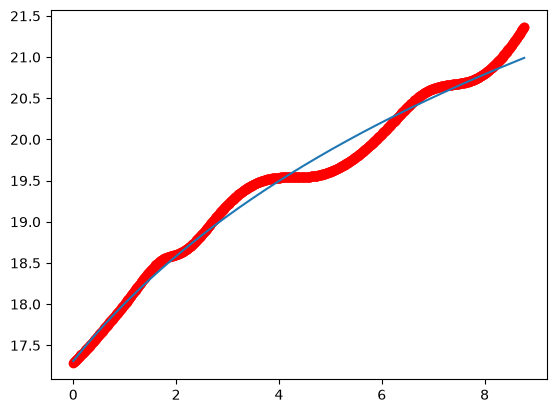

In [7]:
t_0_fit_lum1, M_fit_lum1 = popt_lum1

print(t_0_fit_lum1)
print(M_fit_lum1)

y_lum1 = power_law(t, t_0_fit_lum1, M_fit_lum1)

fig, axs = plt.subplots()
axs.scatter(t, lum1, color = 'r')
axs.plot(t, y_lum1)


In [8]:
init_guess = [np.min(t)-1, np.mean(lum2)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum2, pcov_lum2 = curve_fit(power_law, t, lum2, p0=init_guess, bounds=bounds)

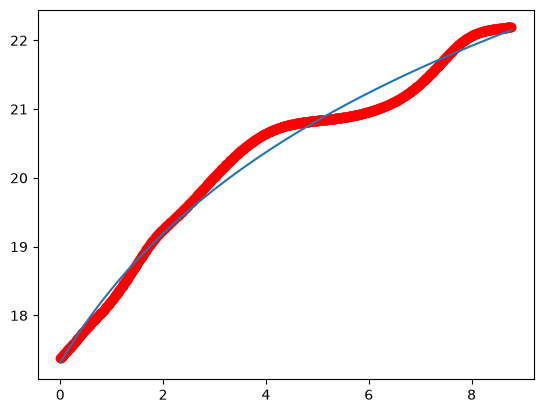

In [9]:
t_0_fit_lum2, M_fit_lum2 = popt_lum2

y_lum2 = power_law(t, t_0_fit_lum2, M_fit_lum2)

fig, axs = plt.subplots()
axs.scatter(t, lum2, color = 'r')
axs.plot(t, y_lum2)


In [10]:
init_guess = [np.min(t)-1, np.mean(lum3)]

bounds = ([-np.inf, -np.inf],
          [np.min(t) - 1e-8, np.inf])

popt_lum3, pcov_lum3 = curve_fit(power_law, t[0:435], lum3, p0=init_guess, bounds=bounds)

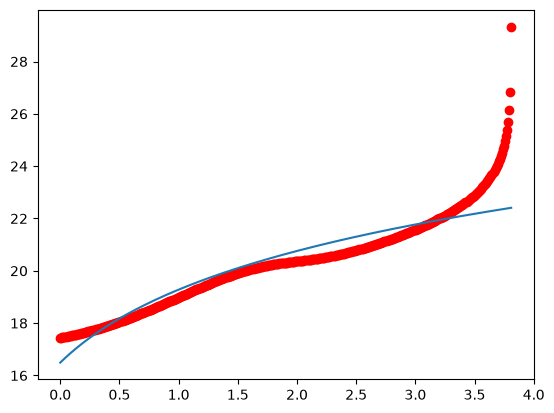

In [11]:
t_0_fit_lum3, M_fit_lum3 = popt_lum3

y_lum3 = power_law(t[0:435], t_0_fit_lum3, M_fit_lum3)

fig, axs = plt.subplots()
axs.scatter(t[0:435], lum3, color = 'r')
axs.plot(t[0:435], y_lum3)


In [27]:
class MetropolisHastings():

    def __init__(self):
        self.theta_chain = []

    def set_proposal_sigma(self, sigma):
        self.proposal_sigma = np.array(sigma)

    def set_target_distribution(self, function):
        self.target_distribution = function

    def initialize(self, theta_init, nsteps):
        self.theta_init = np.array(theta_init)
        self.nsteps = nsteps

    def sample(self):

        self.theta_chain = [self.theta_init.copy()]

        for i in range(self.nsteps):

            theta_prime = np.random.multivariate_normal(mean=self.theta_init, cov=np.diag(self.proposal_sigma**2))

            log_diff = (self.target_distribution(theta_prime) - self.target_distribution(self.theta_init))

            if np.log(np.random.uniform()) < min(0, log_diff):
                self.theta_init = theta_prime

            self.theta_chain.append(self.theta_init.copy())

        return np.array(self.theta_chain)

    def plot_corner(self):
        fig = corner.corner(np.array(self.theta_chain))
        return fig

In [36]:
lum1_err = at2017['flux_error_ztfi'].to_numpy()
lum1_err = np.array(lum1_err)

In [37]:
def log_likelihood_lum1(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum1 - model) / lum1_err)**2+ np.log(2 * np.pi * lum1_err**2))

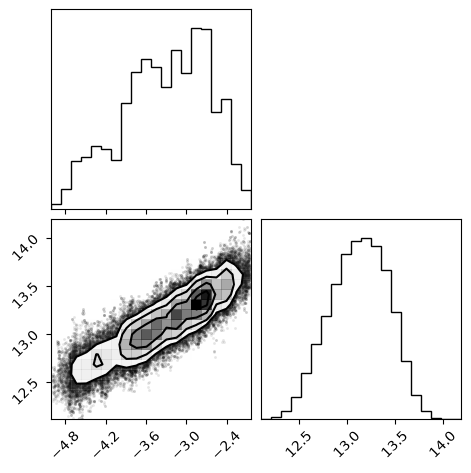

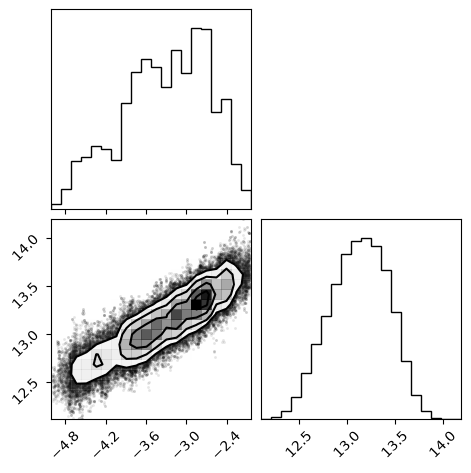

In [ ]:
sampler = MetropolisHastings()

sampler.set_proposal_sigma([0.01, 0.1])

sampler.set_target_distribution(log_likelihood_lum1)

sampler.initialize(theta_init=[t_0_fit_lum1, M_fit_lum1], nsteps=100000)

samples = sampler.sample()

sampler.plot_corner()

In [41]:
lum2_err = at2017['flux_error_ztfr'].to_numpy()
lum2_err = np.array(lum2_err)

In [42]:
def log_likelihood_lum2(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum2 - model) / lum2_err)**2+ np.log(2 * np.pi * lum2_err**2))

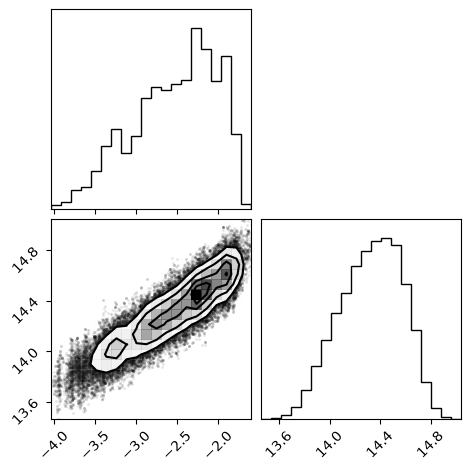

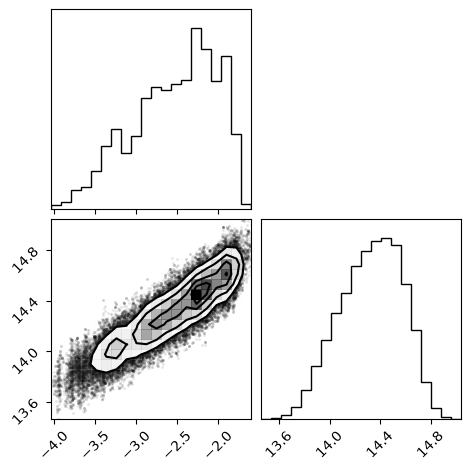

In [44]:
sampler2 = MetropolisHastings()

sampler2.set_proposal_sigma([0.01, 0.1])

sampler2.set_target_distribution(log_likelihood_lum2)

sampler2.initialize(theta_init=[t_0_fit_lum2, M_fit_lum2], nsteps=100000)

samples = sampler2.sample()

sampler2.plot_corner()

In [45]:
lum3_err = at2017['flux_error_ztfg'].to_numpy()
lum3_err = np.array(lum3_err)

In [46]:
def log_likelihood_lum3(theta):

    t_0, M = theta

    if t_0 >= np.min(t):
        return -np.inf

    model = power_law(t, t_0, M)

    return -0.5 * np.sum(((lum3 - model) / lum3_err)**2+ np.log(2 * np.pi * lum3_err**2))

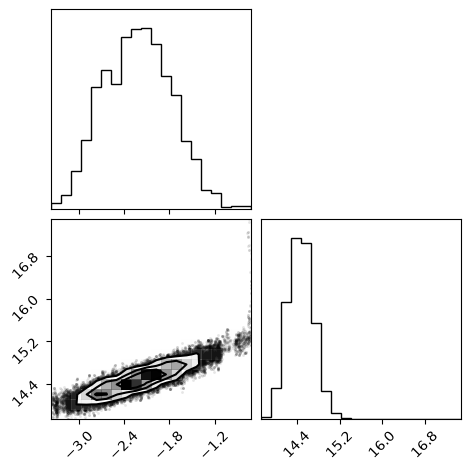

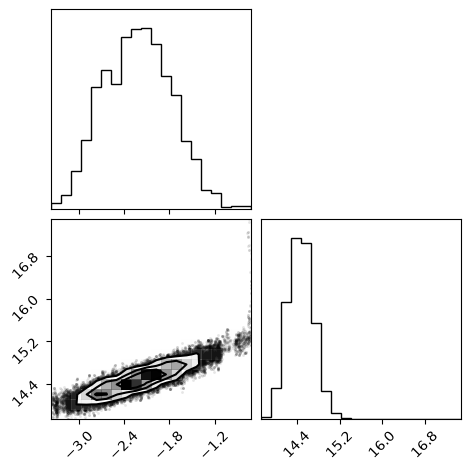

In [47]:
sampler3 = MetropolisHastings()

sampler3.set_proposal_sigma([0.01, 0.1])

sampler3.set_target_distribution(log_likelihood_lum2)

sampler3.initialize(theta_init=[t_0_fit_lum3, M_fit_lum3], nsteps=100000)

samples = sampler3.sample()

sampler3.plot_corner()